<a href="https://colab.research.google.com/github/nadatabai/AquaSense-Tunisia/blob/main/AquaSense_Tunisia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AquaSense Tunisia



# 1. Introduction

## 1.1 Background and Context

Water scarcity is one of the major environmental and agricultural challenges facing many countries around the world. This issue is particularly important in Tunisia, where agriculture is highly dependent on climatic conditions, especially rainfall and water availability.

Climate change, rising temperatures, irregular precipitation patterns, and prolonged drought periods increase pressure on agricultural water resources. These conditions can negatively affect crop growth, agricultural productivity, and food security.

One of the main challenges in agriculture is identifying and anticipating water stress before it causes significant damage to crops. Traditional monitoring methods often depend on field observations and periodic measurements, which may not provide sufficient information for early detection and large-scale monitoring.

Recent developments in Artificial Intelligence (AI), Machine Learning (ML), and remote sensing offer new opportunities to address these challenges. By analyzing historical climate records, satellite observations, and environmental variables, intelligent systems can identify patterns, monitor environmental changes, and predict potential drought and water-stress conditions.

## 1.2 Problem Statement

In Tunisia, agricultural water management remains challenging due to the irregular distribution of rainfall, increasing temperatures, and limited water resources.

Farmers and agricultural decision-makers need reliable information to understand changing climatic conditions and anticipate periods of water scarcity.

However, several difficulties remain:

- Limited access to continuous and reliable agricultural monitoring data.
- Difficulty in identifying drought patterns early.
- Increasing variability in rainfall and temperature.
- Limited use of predictive analytical tools in agricultural decision-making.
- Difficulty in combining different environmental data sources to obtain meaningful insights.

Therefore, there is a need for an intelligent, data-driven system capable of analyzing environmental conditions and predicting potential agricultural water-stress risks.

## 1.3 Project Motivation

The motivation behind AquaSense Tunisia is to explore how Artificial Intelligence and Data Science can contribute to more sustainable agricultural water management.

Rather than relying only on historical observations, this project aims to use predictive models to identify environmental patterns and anticipate future conditions.

The project focuses on Tunisia because of its vulnerability to water scarcity and the importance of agriculture to its economy and food security.

By combining climate data, satellite observations, and Machine Learning techniques, AquaSense aims to transform raw environmental data into useful information that can support agricultural monitoring and decision-making.

## 1.4 Project Objectives

The main objective of AquaSense Tunisia is to develop an AI-based system for monitoring and predicting agricultural water-stress risks.

The specific objectives are:

1. **Climate Data Collection:** Collect historical meteorological data, including temperature, precipitation, relative humidity, and wind speed.

2. **Data Integration:** Combine different environmental datasets, including meteorological and satellite observations.

3. **Exploratory Data Analysis:** Identify climatic trends, seasonal variations, correlations, and potential drought patterns.

4. **Drought Indicator Development:** Calculate the Standardized Precipitation Index (SPI) to characterize meteorological drought conditions.

5. **Predictive Modeling:** Develop and compare Machine Learning and Deep Learning models to predict future drought-related risks.

6. **Model Evaluation:** Evaluate predictive performance using appropriate statistical metrics.

7. **Decision Support:** Develop an interactive dashboard to visualize environmental indicators, predictions, and risk levels.

## 1.5 Proposed Approach

The project follows a structured Data Science and Artificial Intelligence workflow.

First, historical meteorological data will be collected from reliable open-data sources such as NASA POWER and CHIRPS.

Next, the collected data will undergo preprocessing, cleaning, and exploratory analysis to identify missing values, seasonal patterns, and relationships between environmental variables.

Afterwards, drought indicators such as SPI will be calculated to characterize precipitation anomalies.

Several predictive models, including Random Forest, XGBoost, and Long Short-Term Memory (LSTM) networks, will then be developed and compared.

Finally, the results will be integrated into an interactive dashboard to facilitate the visualization and interpretation of predictions.

## 1.6 Expected Outcomes

At the end of the project, AquaSense Tunisia is expected to provide:

- A structured historical climate dataset for the selected study area.
- An analysis of climatic trends and precipitation variability.
- A drought-monitoring approach based on scientific indicators.
- Predictive models for future drought-related conditions.
- A comparative evaluation of Machine Learning and Deep Learning algorithms.
- An interactive dashboard for environmental data visualization.

The project will also provide an opportunity to investigate the potential and limitations of AI-based approaches in agricultural water management.

## 1.7 Project Scope

The initial implementation will focus on Kairouan, Tunisia, as a pilot study area.

The first development phase will concentrate on meteorological drought prediction using historical climate data.

In subsequent phases, satellite-derived indicators and additional environmental variables will be integrated to improve the assessment of agricultural water-stress risks.

It is important to distinguish meteorological drought from actual crop water stress. Predicting crop-level stress requires additional information, such as vegetation indicators, soil moisture, crop characteristics, and field observations.

Therefore, the project will progressively expand from meteorological drought analysis toward a more comprehensive agricultural water-stress monitoring system.

# 2. Libraries Installation and Import

In [3]:
!pip install pandas numpy matplotlib seaborn scikit-learn requests

In [4]:
import os
folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "models",
    "reports"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project structure created successfully!")

Project structure created successfully!


# 3. Data Collection

Data collection is a fundamental step in the development of AquaSense Tunisia. The quality and reliability of the collected data directly influence the performance of the predictive models.

In this project, historical meteorological data will be collected to analyze climatic conditions and investigate drought-related patterns in Kairouan, Tunisia.

The collected dataset includes daily measurements of temperature, relative humidity, precipitation, and wind speed over a 25-year period (2001–2025).

The data will be obtained from NASA POWER, an open-access database providing meteorological and solar-related information for research and agricultural applications.

## 3.1 Study Area

The initial study area selected for AquaSense Tunisia is Kairouan, located in central Tunisia.

Kairouan is an important agricultural region characterized by a semi-arid climate, relatively low and irregular rainfall, and high temperatures during summer.

These climatic conditions make the region relevant for studying precipitation variability, drought patterns, and agricultural water management.

The geographical coordinates used to retrieve meteorological data are:

- **Latitude:** 35.6781° N
- **Longitude:** 10.0963° E
- **Country:** Tunisia

Kairouan will serve as the pilot study area for the initial development and evaluation of the proposed predictive system.

## 3.2 Data Source

The primary data source used in this project is NASA POWER (Prediction of Worldwide Energy Resources).

NASA POWER is an open-access platform developed by NASA that provides meteorological and solar-related datasets for different geographical locations worldwide.

It offers historical environmental observations and estimates that can be used in agricultural, climatic, and environmental studies.

For AquaSense Tunisia, the NASA POWER Daily API will be used to retrieve meteorological variables at the selected geographical coordinates.

**Data source:** NASA POWER

**API:** Daily Point API

**Community:** AG (Agroclimatology)

**Temporal Resolution:** Daily

**Study Period:** January 2001 – December 2025

**Official website:** https://power.larc.nasa.gov/

The selected variables will help us investigate the relationships between temperature, precipitation, humidity, and wind speed.

## 3.3 Data Acquisition

Meteorological data are collected using the NASA POWER API through Python.

The API request specifies the geographical coordinates, observation period, selected meteorological parameters, and data format.

The returned JSON response is transformed into a Pandas DataFrame to facilitate further processing and analysis.

The dataset is then exported as a CSV file and stored in the project's raw data directory.

The following variables are collected:

In [5]:

# Import Libraries
import requests
import pandas as pd
import os

# Define Study Area
LATITUDE = 35.6781
LONGITUDE = 10.0963

# Define Study Period
START_DATE = "20010101"
END_DATE = "20251231"

# Select Meteorological Parameters
PARAMETERS = [
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "RH2M",
    "PRECTOTCORR",
    "WS10M"
]

# Define NASA POWER API
url = "https://power.larc.nasa.gov/api/temporal/daily/point"

# Define API Parameters
params = {
    "parameters": ",".join(PARAMETERS),
    "community": "AG",
    "longitude": LONGITUDE,
    "latitude": LATITUDE,
    "start": START_DATE,
    "end": END_DATE,
    "format": "JSON"
}

# Send API Request
response = requests.get(url, params=params, timeout=120)
response.raise_for_status()

# Extract JSON Data
data = response.json()
weather = data["properties"]["parameter"]

# Convert Data into DataFrame
df = pd.DataFrame(weather)

# Convert Index into Datetime
df.index = pd.to_datetime(df.index, format="%Y%m%d")
df.index.name = "DATE"

# Replace Missing Value Indicators
df = df.replace(-999, float("nan"))

# Create Output Directory
os.makedirs("data/raw", exist_ok=True)

# Export Dataset
df.to_csv("data/raw/kairouan_weather.csv")

print("Data downloaded successfully!")
print("Dataset shape:", df.shape)


Data downloaded successfully!
Dataset shape: (9131, 6)


## 3.4 Data Storage

After data acquisition, the collected meteorological observations are stored in CSV format.

The original dataset is saved in the `data/raw/` directory to preserve the collected information before applying any preprocessing operations.

**Output file:** `kairouan_weather.csv`

This separation between raw and processed data ensures better data organization, reproducibility, and traceability throughout the project.

# 4. Data Exploration

Data exploration is an essential step in understanding the structure and quality of the collected dataset.

Before performing statistical analysis or developing predictive models, it is important to examine the available observations, identify variable types, verify dataset dimensions, and detect missing values.

This section provides an initial overview of the meteorological dataset collected for Kairouan.

In [6]:

# Display First Five Observations
print("First 5 rows:")
display(df.head())

# Display Dataset Information
print("Dataset information:")
df.info()

# Display Dataset Dimensions
print("Dataset shape:", df.shape)

# Check Missing Values
print("Missing values:")
print(df.isnull().sum())


First 5 rows:


,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS10M
DATE,,,,,,
2001-01-01,9.21,16.20,4.74,60.91,0.01,4.72
2001-01-02,11.06,21.55,4.13,45.87,0.00,3.17
2001-01-03,11.19,18.72,5.88,58.27,0.00,3.21
2001-01-04,12.24,20.29,6.32,57.55,0.00,2.27
2001-01-05,13.19,22.35,6.92,57.57,0.00,4.18


Dataset information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 9131 entries, 2001-01-01 to 2025-12-31
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   T2M          9131 non-null   float64
 1   T2M_MAX      9131 non-null   float64
 2   T2M_MIN      9131 non-null   float64
 3   RH2M         9131 non-null   float64
 4   PRECTOTCORR  9131 non-null   float64
 5   WS10M        9131 non-null   float64
dtypes: float64(6)
memory usage: 499.4 KB
Dataset shape: (9131, 6)
Missing values:
T2M            0
T2M_MAX        0
T2M_MIN        0
RH2M           0
PRECTOTCORR    0
WS10M          0
dtype: int64


## 4.1 Statistical Summary

Descriptive statistical analysis is performed to understand the distribution and characteristics of the collected meteorological variables.

The main statistical measures include the mean, standard deviation, minimum, maximum, median, and quartiles.

These indicators help identify the general climatic characteristics of the study area and detect potential anomalies in the dataset.

In [7]:
# Generate Descriptive Statistics
display(df.describe())

,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS10M
count,9131.000000,9131.000000,9131.000000,9131.000000,9131.000000,9131.000000
mean,19.435950,26.818495,13.459837,58.510266,1.049027,3.919483
std,7.609876,8.480393,6.754879,14.126771,3.334727,1.509196
min,3.260000,7.310000,-2.930000,15.760000,0.000000,1.040000
25%,12.670000,19.670000,7.545000,47.710000,0.000000,2.800000
50%,18.970000,26.450000,13.010000,58.710000,0.040000,3.650000
75%,26.005000,33.940000,19.410000,69.530000,0.540000,4.710000
max,38.780000,49.780000,30.200000,96.560000,80.010000,13.550000


## 4.2 Data Visualization Setup

Data visualization is an essential component of Exploratory Data Analysis (EDA). It allows us to understand the distribution, variability, and relationships between meteorological variables.

In this section, different visualization techniques are used to analyze temperature, precipitation, relative humidity, and wind speed.

The objective is to identify climatic patterns, seasonal variations, potential anomalies, and relationships that may be useful for future predictive modeling.

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Configure figure size
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

## 4.3 Temperature Analysis

Temperature is an important meteorological variable influencing agricultural water demand and evaporation.

Analyzing temperature variations helps us understand seasonal climatic patterns and identify periods of extreme heat.

In this section, we examine average, maximum, and minimum daily temperatures over the study period.

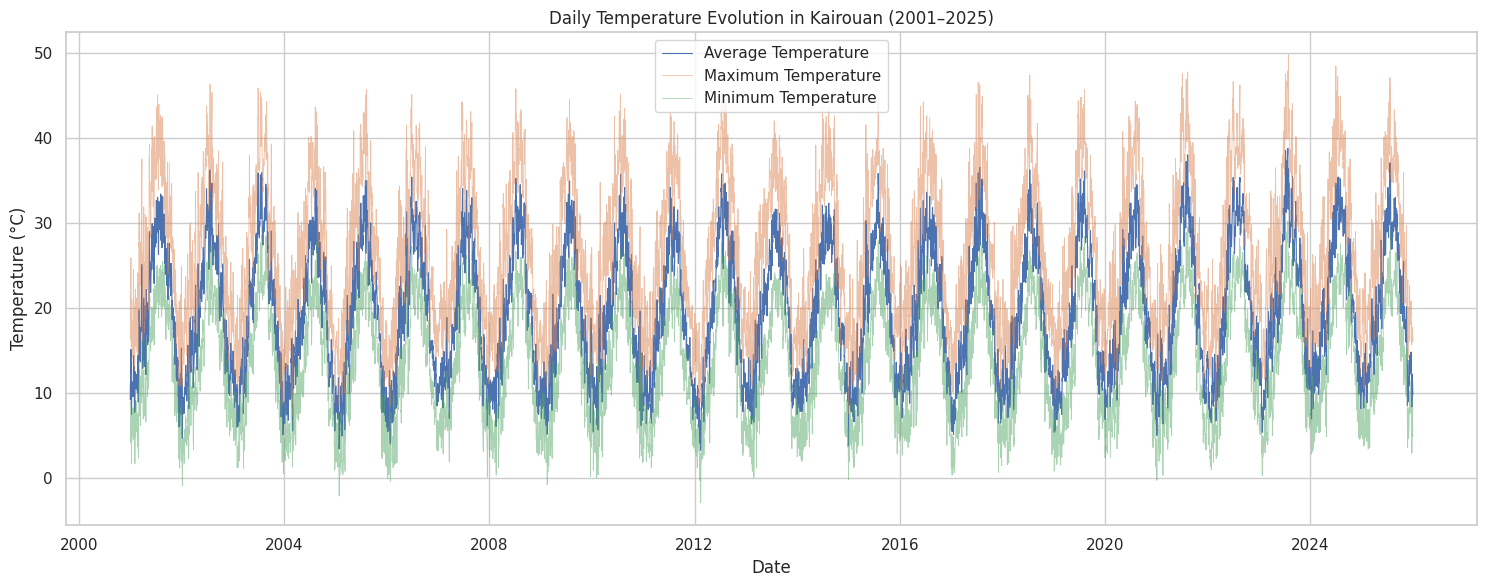

In [9]:
plt.figure(figsize=(15, 6))

plt.plot(df.index, df["T2M"],
         label="Average Temperature",
         linewidth=0.8)

plt.plot(df.index, df["T2M_MAX"],
         label="Maximum Temperature",
         alpha=0.5,
         linewidth=0.6)

plt.plot(df.index, df["T2M_MIN"],
         label="Minimum Temperature",
         alpha=0.5,
         linewidth=0.6)

plt.title("Daily Temperature Evolution in Kairouan (2001–2025)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()

## 4.4 Precipitation Analysis

Precipitation is one of the most important variables in agricultural drought analysis.

The amount and distribution of rainfall directly influence soil water availability and agricultural conditions.

In this section, we analyze daily and monthly precipitation patterns to identify dry periods, rainfall variability, and seasonal differences.

Monthly precipitation will be calculated by aggregating daily precipitation values.

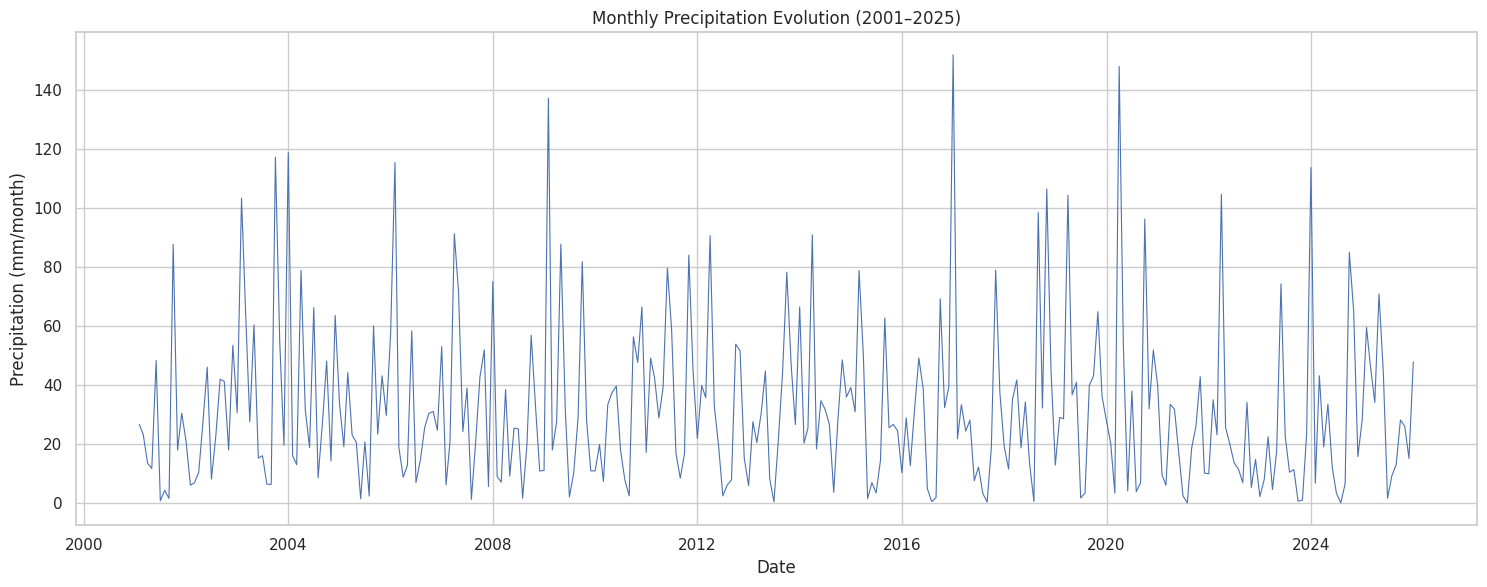

In [10]:
# Calculate Monthly Precipitation
monthly_rain = df["PRECTOTCORR"].resample("ME").sum()

# Plot Monthly Precipitation
plt.figure(figsize=(15, 6))

plt.plot(monthly_rain.index, monthly_rain.values,
         linewidth=0.8)

plt.title("Monthly Precipitation Evolution (2001–2025)")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm/month)")
plt.tight_layout()
plt.show()

## 4.5 Seasonal Precipitation Analysis

Rainfall distribution varies throughout the year due to seasonal climatic conditions.

Analyzing monthly rainfall patterns helps identify the wettest and driest periods in Kairouan.

This analysis is important for understanding the seasonal distribution of water availability and identifying periods that may require particular attention in agricultural water management.

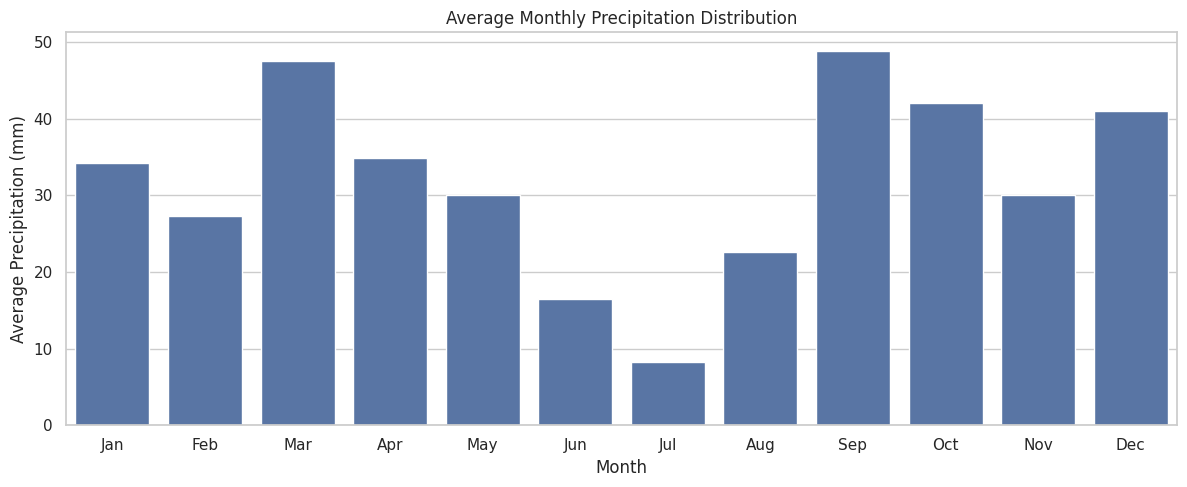

In [11]:
# Calculate Average Monthly Precipitation
monthly_avg_rain = df["PRECTOTCORR"].resample("ME").sum()
monthly_avg_rain = monthly_avg_rain.groupby(
    monthly_avg_rain.index.month
).mean()

# Plot Average Monthly Rainfall
plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_avg_rain.index,
    y=monthly_avg_rain.values
)

plt.title("Average Monthly Precipitation Distribution")
plt.xlabel("Month")
plt.ylabel("Average Precipitation (mm)")
plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.tight_layout()
plt.show()

## 4.6 Relative Humidity Analysis

Relative humidity represents the amount of water vapor present in the atmosphere compared with the maximum amount it can hold at a given temperature.

It is an important environmental variable because it influences evapotranspiration and atmospheric water demand.

In this section, we analyze the evolution and distribution of relative humidity in Kairouan.

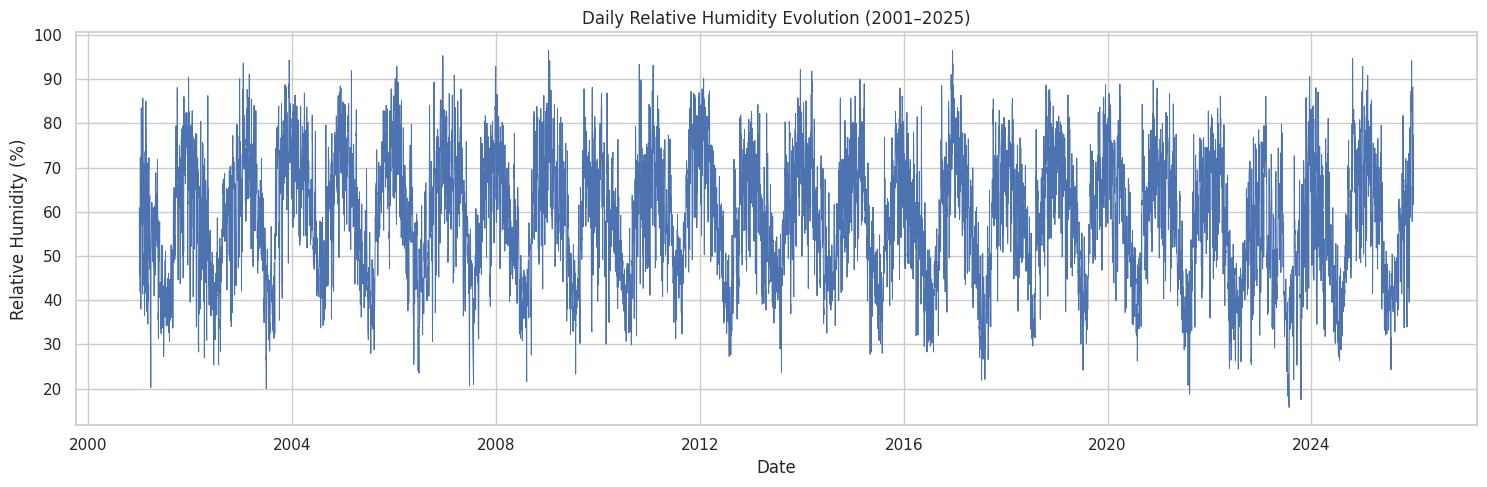

In [13]:
plt.figure(figsize=(15, 5))

plt.plot(df.index, df["RH2M"],
         linewidth=0.7)

plt.title("Daily Relative Humidity Evolution (2001–2025)")
plt.xlabel("Date")
plt.ylabel("Relative Humidity (%)")

plt.tight_layout()
plt.show()

## 4.7 Wind Speed Analysis

Wind speed is another meteorological variable that can influence agricultural water loss through its effect on evapotranspiration.

Higher wind speeds can increase the rate of water transfer from soil and plant surfaces to the atmosphere.

This section examines the temporal variation and statistical distribution of wind speed in the study area.

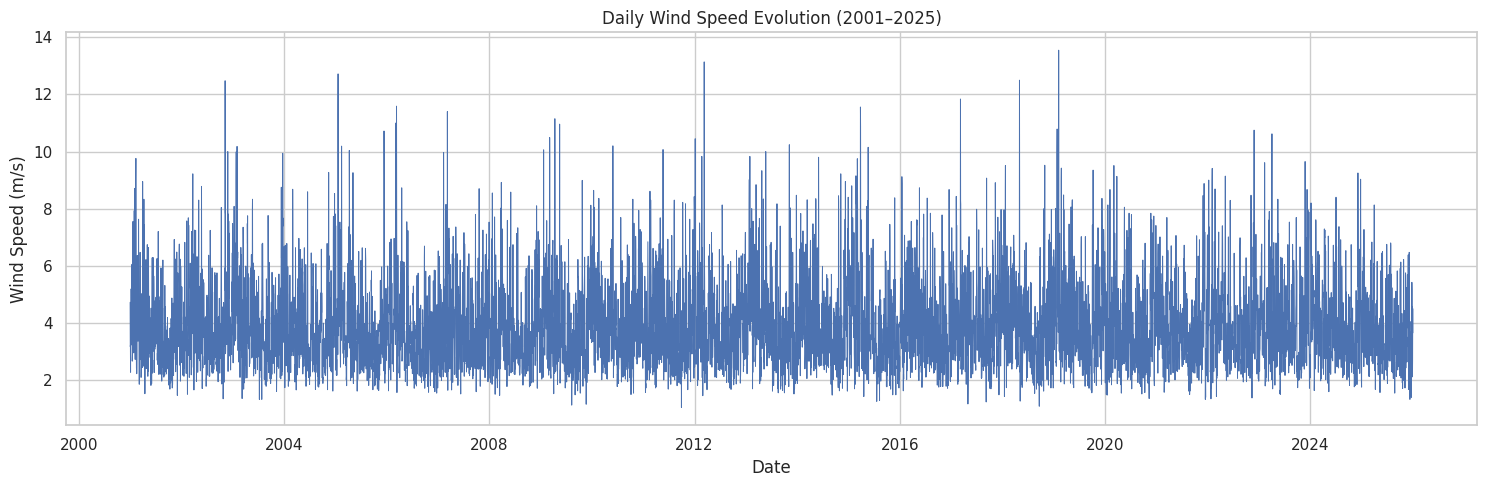

In [14]:
plt.figure(figsize=(15, 5))

plt.plot(df.index, df["WS10M"],
         linewidth=0.7)

plt.title("Daily Wind Speed Evolution (2001–2025)")
plt.xlabel("Date")
plt.ylabel("Wind Speed (m/s)")

plt.tight_layout()
plt.show()

## 4.8 Distribution Analysis

Distribution analysis helps us understand the statistical characteristics of meteorological variables.

Histograms and boxplots are used to examine the frequency, spread, central tendency, and potential extreme values of the collected observations.

This analysis can also help identify skewed distributions and possible outliers that may require further investigation.

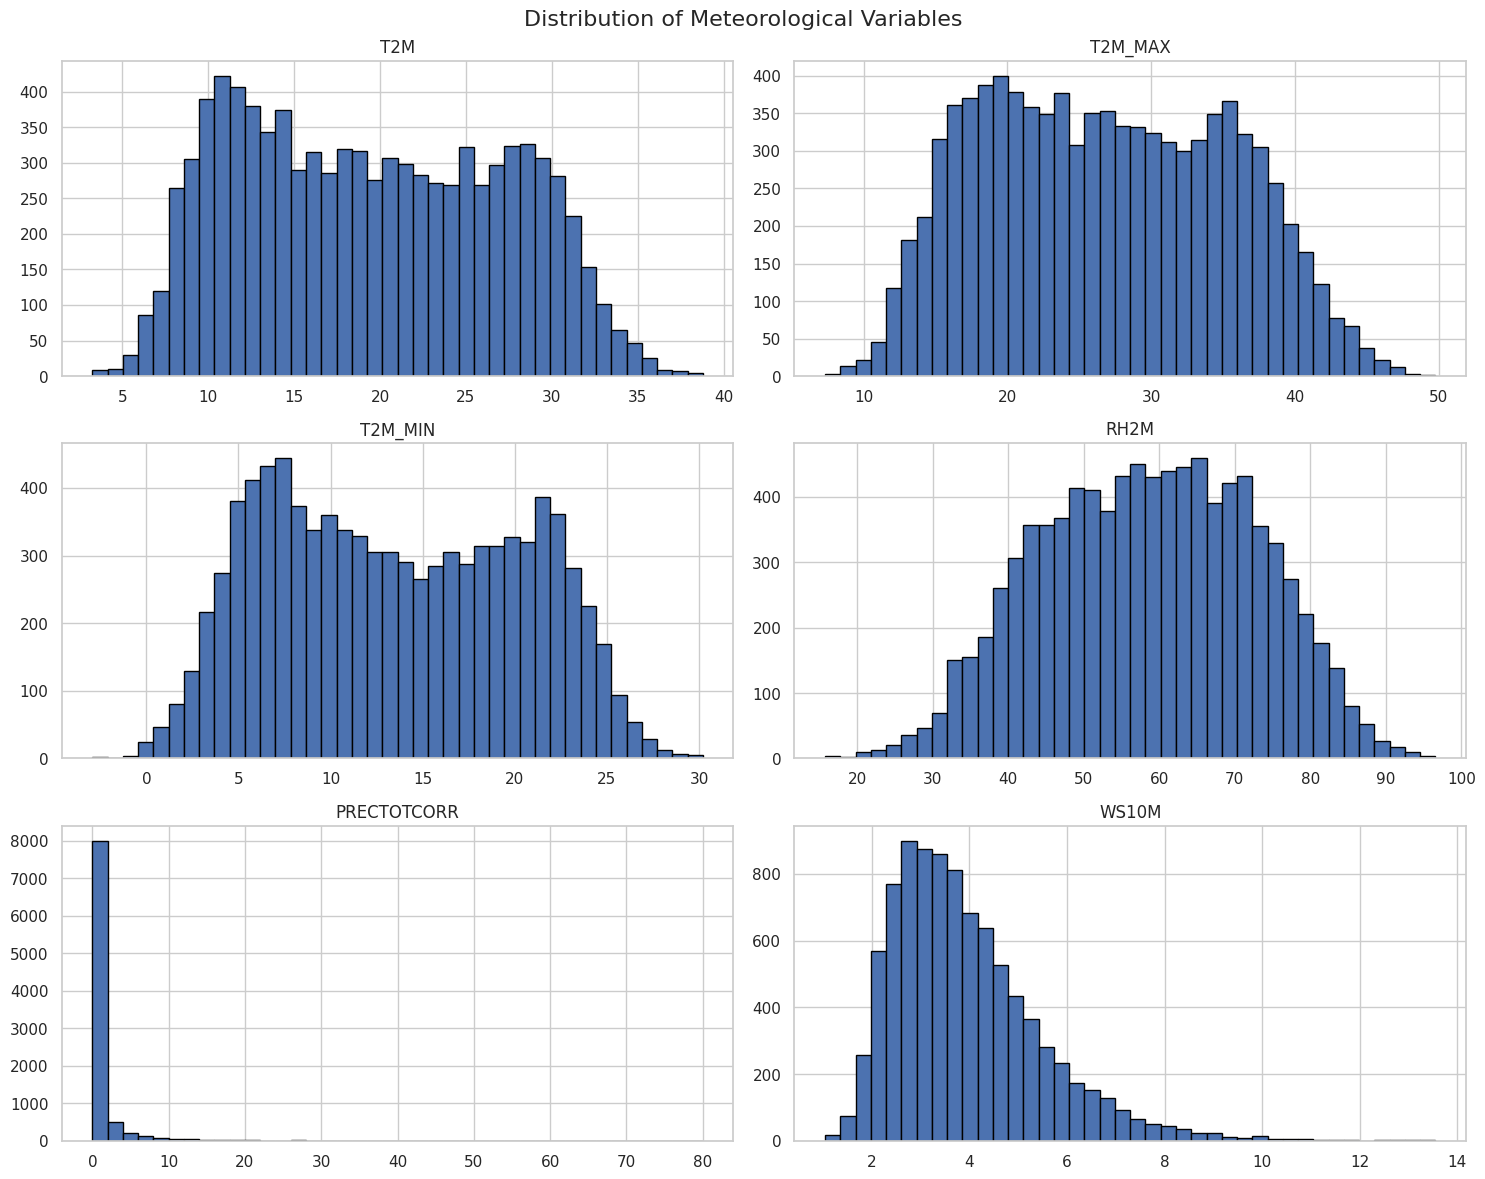

In [15]:
variables = [
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "RH2M",
    "PRECTOTCORR",
    "WS10M"
]

df[variables].hist(
    figsize=(15, 12),
    bins=40,
    edgecolor="black"
)

plt.suptitle("Distribution of Meteorological Variables",
             fontsize=16)

plt.tight_layout()
plt.show()

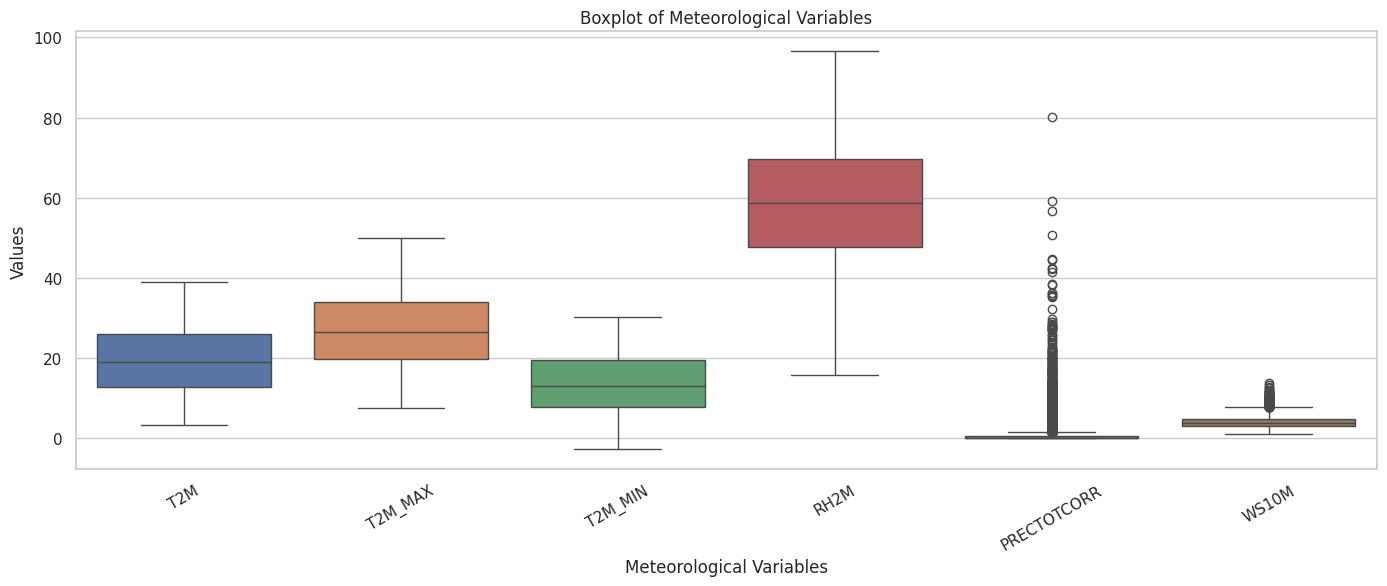

In [16]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=df[variables])

plt.title("Boxplot of Meteorological Variables")
plt.xlabel("Meteorological Variables")
plt.ylabel("Values")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4.9 Correlation Analysis

Correlation analysis is used to investigate the statistical relationships between meteorological variables.

A correlation matrix measures the strength and direction of linear relationships between numerical variables.

The Pearson correlation coefficient ranges from -1 to +1:

- +1 indicates a perfect positive linear relationship.
- -1 indicates a perfect negative linear relationship.
- 0 indicates no linear correlation.

This analysis helps identify relationships between temperature, precipitation, relative humidity, and wind speed.

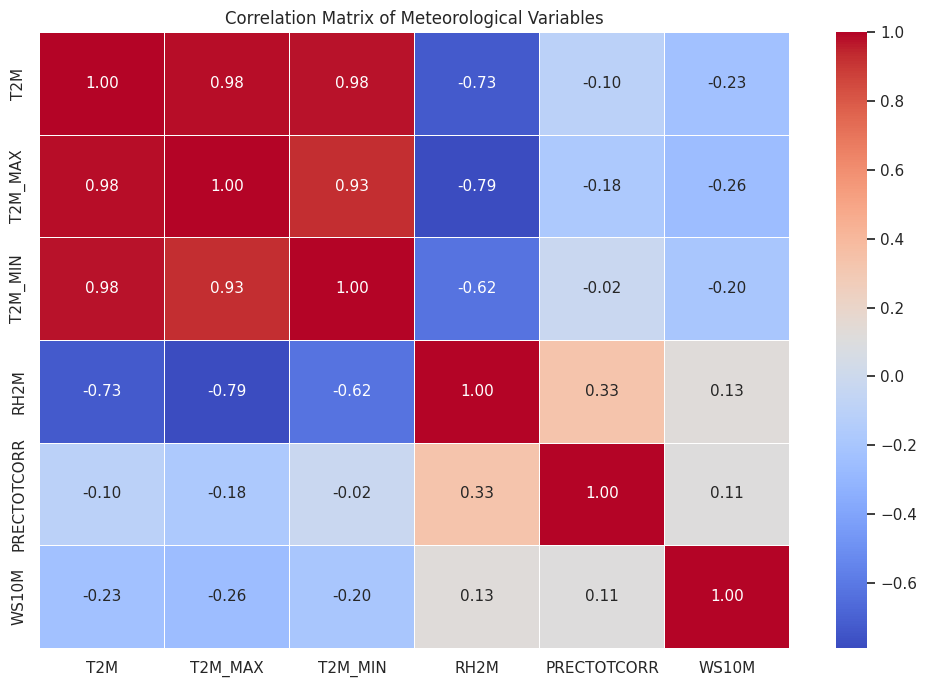

In [18]:
# Calculate Correlation Matrix
correlation_matrix = df[variables].corr()

# Plot Correlation Heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Meteorological Variables")
plt.tight_layout()
plt.show()

## 4.10 Monthly Temperature Patterns

Seasonal temperature variations are important for understanding the climatic characteristics of the study area.

A monthly temperature analysis allows us to compare average temperatures across different months and identify the hottest and coolest periods of the year.

This information can help characterize seasonal environmental conditions and support subsequent drought-related analysis.

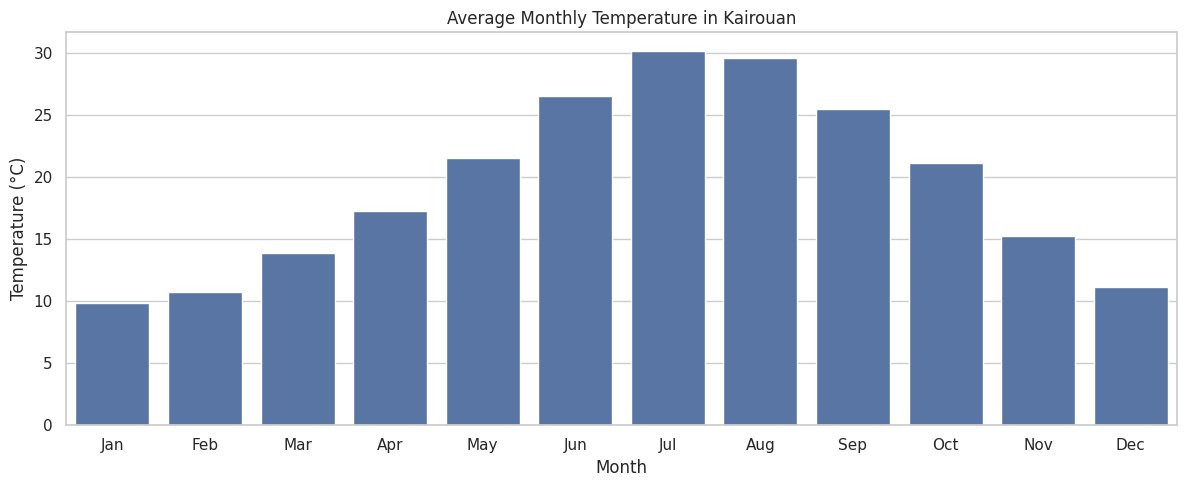

In [20]:
# Calculate Average Temperature by Month
monthly_temp = df["T2M"].groupby(df.index.month).mean()

plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_temp.index,
    y=monthly_temp.values
)

plt.title("Average Monthly Temperature in Kairouan")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.tight_layout()
plt.show()

In [21]:
from google.colab import files

files.download("data/raw/kairouan_weather.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 5. Data Preprocessing and Feature Engineering

This section converts the daily meteorological observations into a consistent monthly dataset suitable for drought monitoring and forecasting. The raw dataset is preserved, while all transformations are applied to a separate working copy.

The target of the first predictive experiment is **meteorological drought risk**, represented by a future SPI-3 value. This is not a direct measurement of soil moisture or crop water stress.

## 5.1 Load and Validate the Raw Dataset

The following checks ensure that the date index is valid, observations are ordered chronologically, and meteorological columns are numeric. Missing values and physically implausible values are inspected before aggregation.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RAW_PATH = Path("data/raw/kairouan_weather.csv")
if not RAW_PATH.exists():
    raise FileNotFoundError(
        "Raw data file not found. Run the Data Acquisition section first."
    )

raw_df = pd.read_csv(RAW_PATH, parse_dates=["DATE"], index_col="DATE")
raw_df = raw_df.sort_index()
raw_df = raw_df[~raw_df.index.duplicated(keep="first")]

expected_columns = [
    "T2M", "T2M_MAX", "T2M_MIN", "RH2M", "PRECTOTCORR", "WS10M"
]
missing_columns = [c for c in expected_columns if c not in raw_df.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

raw_df[expected_columns] = raw_df[expected_columns].apply(
    pd.to_numeric, errors="coerce"
)

# NASA POWER uses -999 as a missing-value indicator.
raw_df[expected_columns] = raw_df[expected_columns].replace(-999, np.nan)

print("Raw dataset shape:", raw_df.shape)
print("Date range:", raw_df.index.min(), "to", raw_df.index.max())
display(raw_df.head())
display(raw_df[expected_columns].isna().sum().to_frame("Missing values"))

Raw dataset shape: (9131, 6)
Date range: 2001-01-01 00:00:00 to 2025-12-31 00:00:00


,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS10M
DATE,,,,,,
2001-01-01,9.21,16.20,4.74,60.91,0.01,4.72
2001-01-02,11.06,21.55,4.13,45.87,0.00,3.17
2001-01-03,11.19,18.72,5.88,58.27,0.00,3.21
2001-01-04,12.24,20.29,6.32,57.55,0.00,2.27
2001-01-05,13.19,22.35,6.92,57.57,0.00,4.18


,Missing values
T2M,0
T2M_MAX,0
T2M_MIN,0
RH2M,0
PRECTOTCORR,0
WS10M,0


## 5.2 Quality Checks

Negative precipitation values and out-of-range relative humidity values are treated as invalid. Temperature and wind values are retained for inspection rather than being automatically removed using arbitrary thresholds.

Rows where T2M_MIN > T2M_MAX: 0


,Missing rate (%)
T2M,0.0
T2M_MAX,0.0
T2M_MIN,0.0
RH2M,0.0
PRECTOTCORR,0.0
WS10M,0.0


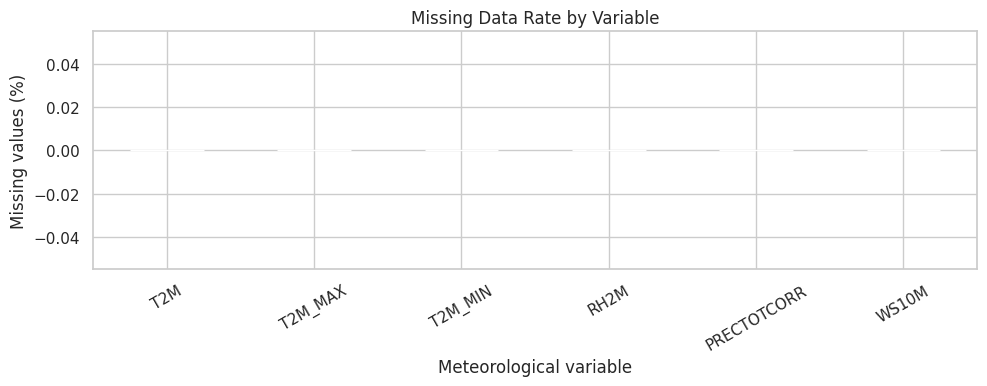

In [24]:
quality_df = raw_df.copy()

quality_df.loc[quality_df["PRECTOTCORR"] < 0, "PRECTOTCORR"] = np.nan
quality_df.loc[~quality_df["RH2M"].between(0, 100), "RH2M"] = np.nan

# Check whether minimum temperature exceeds maximum temperature.
invalid_temp_order = quality_df["T2M_MIN"] > quality_df["T2M_MAX"]
print("Rows where T2M_MIN > T2M_MAX:", int(invalid_temp_order.sum()))

# A compact overview of missingness after basic quality checks.
missing_rate = quality_df.isna().mean().mul(100).sort_values(ascending=False)
display(missing_rate.to_frame("Missing rate (%)"))

plt.figure(figsize=(10, 4))
missing_rate.plot(kind="bar")
plt.title("Missing Data Rate by Variable")
plt.ylabel("Missing values (%)")
plt.xlabel("Meteorological variable")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 5.3 Monthly Aggregation

Drought indicators are generally calculated from accumulated precipitation over consecutive months. Daily precipitation is therefore summed by month, while temperature, humidity, and wind speed are averaged.

A monthly precipitation total is accepted only when at least 90% of the days in that month have valid precipitation observations. This avoids treating an incomplete month as a complete rainfall total.

In [25]:
monthly = pd.DataFrame(index=quality_df.resample("MS").size().index)
monthly.index.name = "DATE"

monthly["precipitation_mm"] = quality_df["PRECTOTCORR"].resample("MS").sum(min_count=1)
monthly["precip_valid_days"] = quality_df["PRECTOTCORR"].resample("MS").count()
monthly["days_in_month"] = monthly.index.days_in_month
monthly["precip_coverage"] = (
    monthly["precip_valid_days"] / monthly["days_in_month"]
)

monthly.loc[monthly["precip_coverage"] < 0.90, "precipitation_mm"] = np.nan

monthly["temperature_mean_c"] = quality_df["T2M"].resample("MS").mean()
monthly["temperature_max_c"] = quality_df["T2M_MAX"].resample("MS").mean()
monthly["temperature_min_c"] = quality_df["T2M_MIN"].resample("MS").mean()
monthly["relative_humidity_pct"] = quality_df["RH2M"].resample("MS").mean()
monthly["wind_speed_ms"] = quality_df["WS10M"].resample("MS").mean()

monthly = monthly.loc[
    (monthly.index >= quality_df.index.min().to_period("M").to_timestamp())
    & (monthly.index <= quality_df.index.max().to_period("M").to_timestamp())
]

print("Monthly dataset shape:", monthly.shape)
display(monthly.head(12))

Monthly dataset shape: (300, 9)


,precipitation_mm,precip_valid_days,days_in_month,precip_coverage,temperature_mean_c,temperature_max_c,temperature_min_c,relative_humidity_pct,wind_speed_ms
DATE,,,,,,,,,
2001-01-01,26.61,31,31,1.0,10.955806,18.229032,6.041613,60.680645,4.279355
2001-02-01,23.17,28,28,1.0,10.865714,18.027500,5.576429,60.919286,4.643571
2001-03-01,13.45,31,31,1.0,17.627097,26.212581,10.780645,50.165484,4.040968
2001-04-01,11.64,30,30,1.0,17.267667,25.429000,10.272667,54.357000,4.507667
2001-05-01,48.29,31,31,1.0,21.883548,29.748065,15.040323,52.918710,4.010000
2001-06-01,0.71,30,30,1.0,27.235000,36.157667,18.969000,39.281000,3.985667
2001-07-01,4.22,31,31,1.0,30.294194,39.486452,22.122581,40.703226,4.012258
2001-08-01,1.54,31,31,1.0,29.703226,37.887097,22.260968,41.767419,3.622581
2001-09-01,87.69,30,30,1.0,25.081333,31.726333,19.754667,62.617667,3.094000


## 5.4 Monthly Dataset Overview

The monthly time series is inspected for gaps and long-term patterns. Missing meteorological predictor values will be imputed inside the model pipeline later, using training data only. Precipitation is not interpolated for SPI calculation because doing so could create artificial rainfall.

Missing values in monthly dataset:


,Missing values
precipitation_mm,0
precip_valid_days,0
days_in_month,0
precip_coverage,0
temperature_mean_c,0
temperature_max_c,0
temperature_min_c,0
relative_humidity_pct,0
wind_speed_ms,0


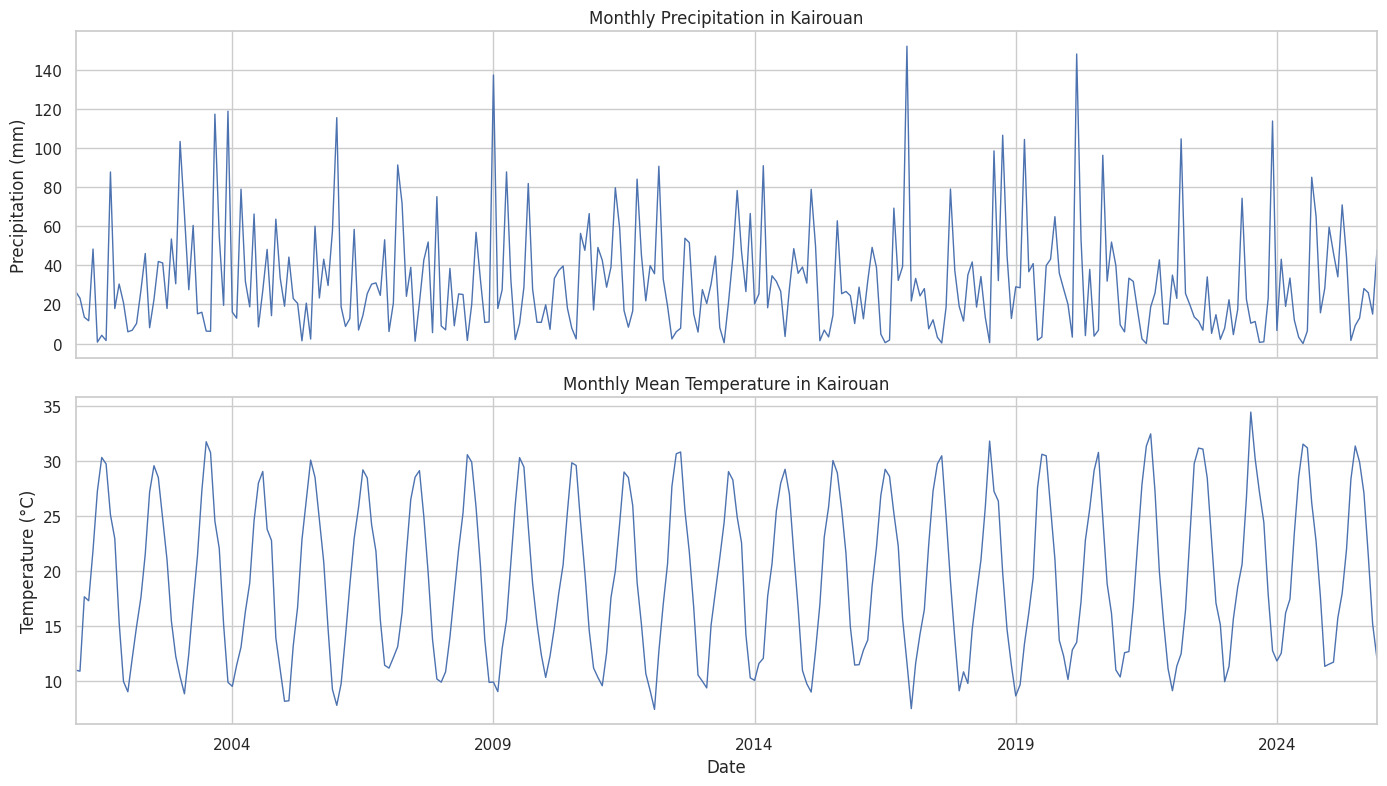

In [26]:
print("Missing values in monthly dataset:")
display(monthly.isna().sum().to_frame("Missing values"))

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
monthly["precipitation_mm"].plot(ax=axes[0], linewidth=1)
axes[0].set_title("Monthly Precipitation in Kairouan")
axes[0].set_ylabel("Precipitation (mm)")

monthly["temperature_mean_c"].plot(ax=axes[1], linewidth=1)
axes[1].set_title("Monthly Mean Temperature in Kairouan")
axes[1].set_ylabel("Temperature (°C)")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

## 5.5 Calculate the Standardized Precipitation Index (SPI-3)

SPI-3 describes precipitation anomalies over a three-month accumulation period. For each calendar month, a gamma distribution is fitted to the historical three-month precipitation totals; the fitted cumulative probability is then transformed to a standard normal value.

The implementation requires a sufficient number of valid historical observations for each calendar month. If the fitting data are insufficient or degenerate, the SPI value is left missing rather than assigning an unreliable score.

In [27]:
from scipy.stats import gamma, norm

monthly["precipitation_3m"] = monthly["precipitation_mm"].rolling(
    window=3, min_periods=3
).sum()

def calculate_spi3(monthly_precipitation, min_samples=15):
    """Calculate calendar-month-specific SPI-3 from monthly precipitation."""
    precipitation_3m = monthly_precipitation.copy()
    spi = pd.Series(index=precipitation_3m.index, dtype=float, name="SPI_3")

    for calendar_month in range(1, 13):
        month_mask = precipitation_3m.index.month == calendar_month
        values = precipitation_3m.loc[month_mask].dropna()

        if len(values) < min_samples:
            continue

        # Gamma distribution is fitted to positive precipitation values.
        positive = values[values > 0]
        if len(positive) < min_samples:
            continue

        try:
            shape, loc, scale = gamma.fit(positive.values, floc=0)
        except (ValueError, RuntimeError):
            continue

        all_values = precipitation_3m.loc[month_mask]
        probabilities = pd.Series(index=all_values.index, dtype=float)

        valid = all_values.notna()
        x = all_values.loc[valid].clip(lower=0)

        # Account for the probability of zero precipitation.
        zero_probability = (values == 0).mean()
        probabilities.loc[valid] = (
            zero_probability
            + (1 - zero_probability) * gamma.cdf(x, a=shape, loc=0, scale=scale)
        )

        probabilities = probabilities.clip(1e-6, 1 - 1e-6)
        spi.loc[probabilities.index] = norm.ppf(probabilities)

    return spi

monthly["SPI_3"] = calculate_spi3(monthly["precipitation_3m"])

print("SPI-3 valid observations:", int(monthly["SPI_3"].notna().sum()))
display(monthly[["precipitation_mm", "precipitation_3m", "SPI_3"]].tail(15))

SPI-3 valid observations: 298


,precipitation_mm,precipitation_3m,SPI_3
DATE,,,
2024-10-01,64.97,156.42,0.903278
2024-11-01,15.70,165.67,0.973873
2024-12-01,28.22,108.89,0.064831
2025-01-01,59.51,103.43,0.113062
2025-02-01,46.26,133.99,0.697469
2025-03-01,34.09,139.86,0.685378
2025-04-01,70.87,151.22,0.912716
2025-05-01,44.06,149.02,0.890171
2025-06-01,1.58,116.51,0.973524


## 5.6 Drought Classification

The following categories follow commonly used SPI interpretation thresholds. They describe meteorological drought severity, not crop damage.

- SPI ≥ 2.0: Extremely wet
- 1.5 to 1.99: Severely wet
- 1.0 to 1.49: Moderately wet
- -0.99 to 0.99: Near normal
- -1.0 to -1.49: Moderately dry
- -1.5 to -1.99: Severely dry
- SPI ≤ -2.0: Extremely dry

For the initial prediction task, drought risk is defined as SPI-3 ≤ -1.0.

In [28]:
def classify_spi(value):
    if pd.isna(value):
        return np.nan
    if value >= 2.0:
        return "Extremely wet"
    if value >= 1.5:
        return "Severely wet"
    if value >= 1.0:
        return "Moderately wet"
    if value > -1.0:
        return "Near normal"
    if value > -1.5:
        return "Moderately dry"
    if value > -2.0:
        return "Severely dry"
    return "Extremely dry"

monthly["drought_class"] = monthly["SPI_3"].apply(classify_spi)
monthly["drought_risk"] = np.where(
    monthly["SPI_3"].notna(),
    (monthly["SPI_3"] <= -1.0).astype(int),
    np.nan
)

display(monthly[["SPI_3", "drought_class", "drought_risk"]].tail(18))

,SPI_3,drought_class,drought_risk
DATE,,,
2024-07-01,-1.746211,Severely dry,1.0
2024-08-01,-1.590626,Severely dry,1.0
2024-09-01,0.468113,Near normal,0.0
2024-10-01,0.903278,Near normal,0.0
2024-11-01,0.973873,Near normal,0.0
2024-12-01,0.064831,Near normal,0.0
2025-01-01,0.113062,Near normal,0.0
2025-02-01,0.697469,Near normal,0.0
2025-03-01,0.685378,Near normal,0.0


## 5.7 SPI-3 Visualization

The SPI-3 time series makes it possible to identify wet and dry periods. The horizontal thresholds at -1 and +1 indicate the beginning of moderate dry and wet conditions.

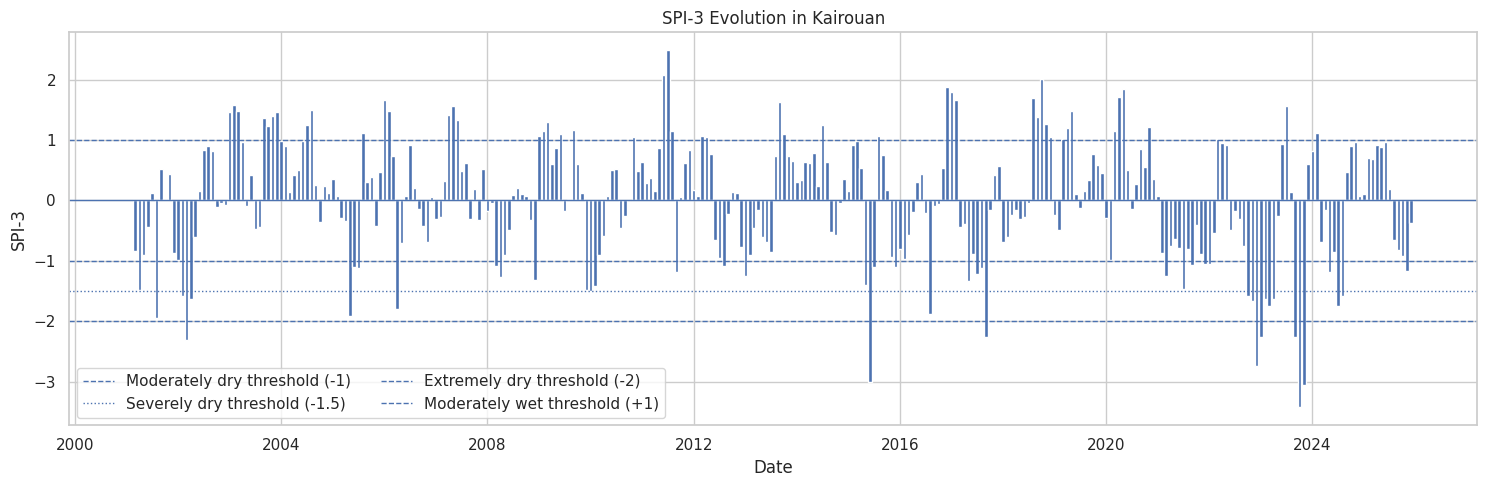

,Number of months
drought_class,
Near normal,204
Moderately wet,34
Moderately dry,24
Severely dry,14
Severely wet,11
Extremely dry,8
Extremely wet,3


In [29]:
plt.figure(figsize=(15, 5))
plt.bar(monthly.index, monthly["SPI_3"], width=25)
plt.axhline(0, linewidth=1)
plt.axhline(-1, linestyle="--", linewidth=1, label="Moderately dry threshold (-1)")
plt.axhline(-1.5, linestyle=":", linewidth=1, label="Severely dry threshold (-1.5)")
plt.axhline(-2, linestyle="--", linewidth=1, label="Extremely dry threshold (-2)")
plt.axhline(1, linestyle="--", linewidth=1, label="Moderately wet threshold (+1)")
plt.title("SPI-3 Evolution in Kairouan")
plt.xlabel("Date")
plt.ylabel("SPI-3")
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

class_counts = monthly["drought_class"].value_counts()
display(class_counts.to_frame("Number of months"))

## 5.8 Feature Engineering

Predictors are created from information available at the end of month *t*. The target is the drought-risk status in month *t+1*. Lagged precipitation, SPI, temperature, humidity, and wind features provide historical context.

The target is shifted backwards by one row so that each feature row is paired with the following month's drought status. No future meteorological values are used as predictors.

In [30]:
feature_data = monthly.copy()

base_features = [
    "precipitation_mm",
    "temperature_mean_c",
    "temperature_max_c",
    "temperature_min_c",
    "relative_humidity_pct",
    "wind_speed_ms",
    "SPI_3"
]

# Calendar features known at prediction time.
feature_data["month_sin"] = np.sin(2 * np.pi * feature_data.index.month / 12)
feature_data["month_cos"] = np.cos(2 * np.pi * feature_data.index.month / 12)

engineered_features = ["month_sin", "month_cos"]

# Lagged values: only current and past observations are used.
for column in base_features:
    for lag in [0, 1, 2, 3]:
        feature_name = f"{column}_lag_{lag}"
        feature_data[feature_name] = feature_data[column].shift(lag)
        engineered_features.append(feature_name)

# Rolling statistics are shifted to ensure they use no future data.
for column in ["precipitation_mm", "temperature_mean_c", "SPI_3"]:
    feature_name = f"{column}_rolling_3m_mean"
    feature_data[feature_name] = (
        feature_data[column].rolling(3, min_periods=2).mean()
    )
    engineered_features.append(feature_name)

# Predict drought risk one month ahead.
feature_data["target_next_month_drought"] = feature_data["drought_risk"].shift(-1)

model_data = feature_data[engineered_features + ["target_next_month_drought"]].copy()
model_data = model_data.dropna(subset=["target_next_month_drought"])
model_data["target_next_month_drought"] = model_data[
    "target_next_month_drought"
].astype(int)

print("Number of engineered features:", len(engineered_features))
print("Model dataset shape before feature imputation:", model_data.shape)
display(model_data.head())

Number of engineered features: 33
Model dataset shape before feature imputation: (298, 34)


,month_sin,month_cos,precipitation_mm_lag_0,precipitation_mm_lag_1,precipitation_mm_lag_2,precipitation_mm_lag_3,temperature_mean_c_lag_0,temperature_mean_c_lag_1,temperature_mean_c_lag_2,temperature_mean_c_lag_3,...,wind_speed_ms_lag_2,wind_speed_ms_lag_3,SPI_3_lag_0,SPI_3_lag_1,SPI_3_lag_2,SPI_3_lag_3,precipitation_mm_rolling_3m_mean,temperature_mean_c_rolling_3m_mean,SPI_3_rolling_3m_mean,target_next_month_drought
DATE,,,,,,,,,,,,,,,,,,,,,
2001-02-01,8.660254e-01,5.000000e-01,23.17,26.61,NaN,NaN,10.865714,10.955806,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,24.890000,10.910760,NaN,0
2001-03-01,1.000000e+00,6.123234e-17,13.45,23.17,26.61,NaN,17.627097,10.865714,10.955806,NaN,...,4.279355,NaN,-0.832767,NaN,NaN,NaN,21.076667,13.149539,NaN,1
2001-04-01,8.660254e-01,-5.000000e-01,11.64,13.45,23.17,26.61,17.267667,17.627097,10.865714,10.955806,...,4.643571,4.279355,-1.481258,-0.832767,NaN,NaN,16.086667,15.253493,-1.157013,0
2001-05-01,5.000000e-01,-8.660254e-01,48.29,11.64,13.45,23.17,21.883548,17.267667,17.627097,10.865714,...,4.040968,4.643571,-0.896430,-1.481258,-0.832767,NaN,24.460000,18.926104,-1.070152,0
2001-06-01,1.224647e-16,-1.000000e+00,0.71,48.29,11.64,13.45,27.235000,21.883548,17.267667,17.627097,...,4.507667,4.040968,-0.445898,-0.896430,-1.481258,-0.832767,20.213333,22.128738,-0.941195,0


## 5.9 Save Processed Datasets

The monthly dataset and the feature table are saved separately. These files make the next stages reproducible and avoid modifying the original daily observations.

In [31]:
from pathlib import Path

Path("data/processed").mkdir(parents=True, exist_ok=True)

monthly.to_csv("data/processed/kairouan_monthly_climate_spi3.csv")
model_data.to_csv("data/processed/kairouan_drought_features.csv")

print("Processed datasets saved:")
print("- data/processed/kairouan_monthly_climate_spi3.csv")
print("- data/processed/kairouan_drought_features.csv")

Processed datasets saved:
- data/processed/kairouan_monthly_climate_spi3.csv
- data/processed/kairouan_drought_features.csv


# 6. Predictive Modeling

The first modeling experiment predicts whether the next month will reach the moderate meteorological drought threshold (SPI-3 ≤ -1). This is a binary classification problem.

Because the observations form a time series, the data are split chronologically. Random shuffling is avoided to reduce information leakage from future periods into the training set.

## 6.1 Chronological Train-Test Split

The final 20% of the available timeline is reserved for testing. The split is based on dates, not random sampling. Model preprocessing, including missing-value imputation and feature scaling where needed, is fitted only on the training data.

In [32]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

model_data = model_data.sort_index()
split_position = int(len(model_data) * 0.80)
train_data = model_data.iloc[:split_position].copy()
test_data = model_data.iloc[split_position:].copy()

X_train = train_data[engineered_features]
y_train = train_data["target_next_month_drought"]
X_test = test_data[engineered_features]
y_test = test_data["target_next_month_drought"]

print("Training period:", train_data.index.min(), "to", train_data.index.max())
print("Testing period:", test_data.index.min(), "to", test_data.index.max())
print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))
print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())

if y_train.nunique() < 2:
    raise ValueError("The training period contains only one target class. "
                     "A binary classifier cannot be trained reliably.")

Training period: 2001-02-01 00:00:00 to 2020-11-01 00:00:00
Testing period: 2020-12-01 00:00:00 to 2025-11-01 00:00:00
Training observations: 238
Testing observations: 60

Training target distribution:


,proportion
target_next_month_drought,
0,0.886555
1,0.113445



Testing target distribution:


,proportion
target_next_month_drought,
0,0.683333
1,0.316667


## 6.2 Train Baseline and Tree-Based Models

Three models are evaluated: Logistic Regression as a simple baseline, Random Forest, and Histogram-based Gradient Boosting. All models use a median imputer. Logistic Regression additionally uses standardization.

If the drought class is rare, class weighting is used for Logistic Regression and Random Forest. The test set remains untouched during training.

In [35]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=42
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=400,
            max_depth=6,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(
            max_iter=150,
            learning_rate=0.05,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            random_state=42
        ))
    ])
}

trained_models = {}
for model_name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[model_name] = model
    print(f"{model_name}: training completed")

Logistic Regression: training completed
Random Forest: training completed
HistGradientBoosting: training completed


## 6.3 Model Evaluation

Accuracy alone can be misleading when drought months are uncommon. Precision, recall, and F1-score are therefore reported for the drought-risk class. ROC-AUC is calculated when both classes are present in the test set.

In [36]:
evaluation_rows = []
test_predictions = {}

for model_name, model in trained_models.items():
    predictions = model.predict(X_test)
    test_predictions[model_name] = predictions

    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    }

    if y_test.nunique() == 2 and hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)[:, 1]
        row["ROC-AUC"] = roc_auc_score(y_test, probabilities)
    else:
        row["ROC-AUC"] = np.nan

    evaluation_rows.append(row)

evaluation_results = pd.DataFrame(evaluation_rows).set_index("Model")
display(evaluation_results.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.717,0.536,0.789,0.638,0.840
Random Forest,0.783,0.875,0.368,0.519,0.798
HistGradientBoosting,0.767,0.727,0.421,0.533,0.806


## 6.4 Confusion Matrices and Classification Reports

The confusion matrix distinguishes correctly identified drought-risk months from missed drought events and false alarms. These errors have different practical consequences and should be considered when interpreting the models.

In [38]:
for model_name, predictions in test_predictions.items():
    print("\n", model_name)
    print(classification_report(
        y_test, predictions,
        labels=[0, 1],
        target_names=["No drought risk", "Drought risk"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    display(
        pd.DataFrame(
            cm,
            index=["Actual: No drought", "Actual: Drought"],
            columns=["Predicted: No drought", "Predicted: Drought"]
        )
    )


 Logistic Regression
                 precision    recall  f1-score   support

No drought risk       0.88      0.68      0.77        41
   Drought risk       0.54      0.79      0.64        19

       accuracy                           0.72        60
      macro avg       0.71      0.74      0.70        60
   weighted avg       0.77      0.72      0.73        60



,Predicted: No drought,Predicted: Drought
Actual: No drought,28,13
Actual: Drought,4,15



 Random Forest
                 precision    recall  f1-score   support

No drought risk       0.77      0.98      0.86        41
   Drought risk       0.88      0.37      0.52        19

       accuracy                           0.78        60
      macro avg       0.82      0.67      0.69        60
   weighted avg       0.80      0.78      0.75        60



,Predicted: No drought,Predicted: Drought
Actual: No drought,40,1
Actual: Drought,12,7



 HistGradientBoosting
                 precision    recall  f1-score   support

No drought risk       0.78      0.93      0.84        41
   Drought risk       0.73      0.42      0.53        19

       accuracy                           0.77        60
      macro avg       0.75      0.67      0.69        60
   weighted avg       0.76      0.77      0.75        60



,Predicted: No drought,Predicted: Drought
Actual: No drought,38,3
Actual: Drought,11,8


## 6.5 Compare Model Performance

The chart compares the F1-score and recall for the drought-risk class. In an early-warning context, recall is especially important because a missed drought-risk month may be more costly than a false alarm. The final model choice should consider both metrics and the small size of the monthly dataset.

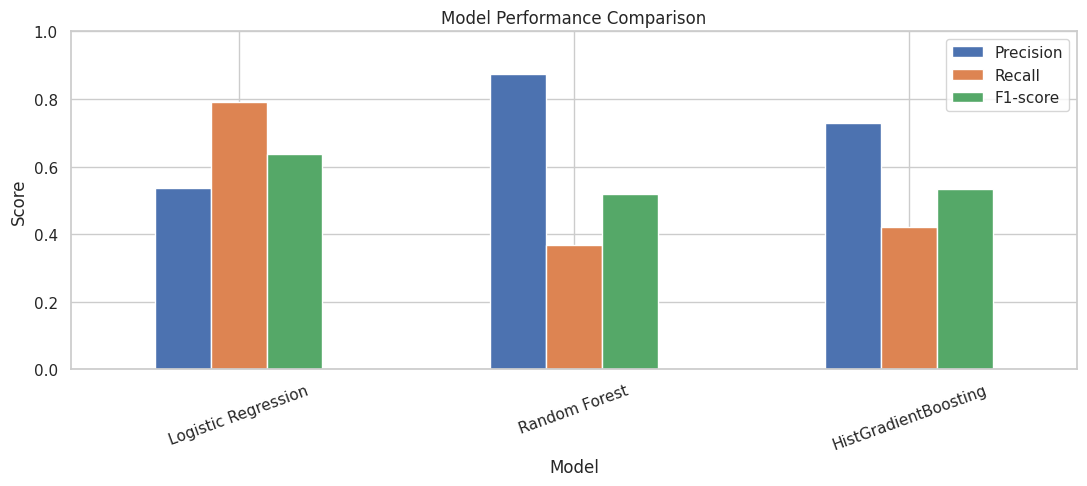

In [39]:
evaluation_results[["Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(11, 5)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 6.6 Feature Importance

Random Forest feature importance is used as an initial indication of which inputs contribute to the fitted model. It describes model behavior, not causality. Correlated lagged features can share or distort importance.

,Random Forest importance
precipitation_mm_lag_0,0.165592
SPI_3_lag_0,0.111981
precipitation_mm_lag_1,0.096032
precipitation_mm_rolling_3m_mean,0.080135
SPI_3_rolling_3m_mean,0.036358
relative_humidity_pct_lag_0,0.034749
precipitation_mm_lag_2,0.031877
temperature_max_c_lag_2,0.031646
precipitation_mm_lag_3,0.027744
temperature_mean_c_lag_2,0.026494


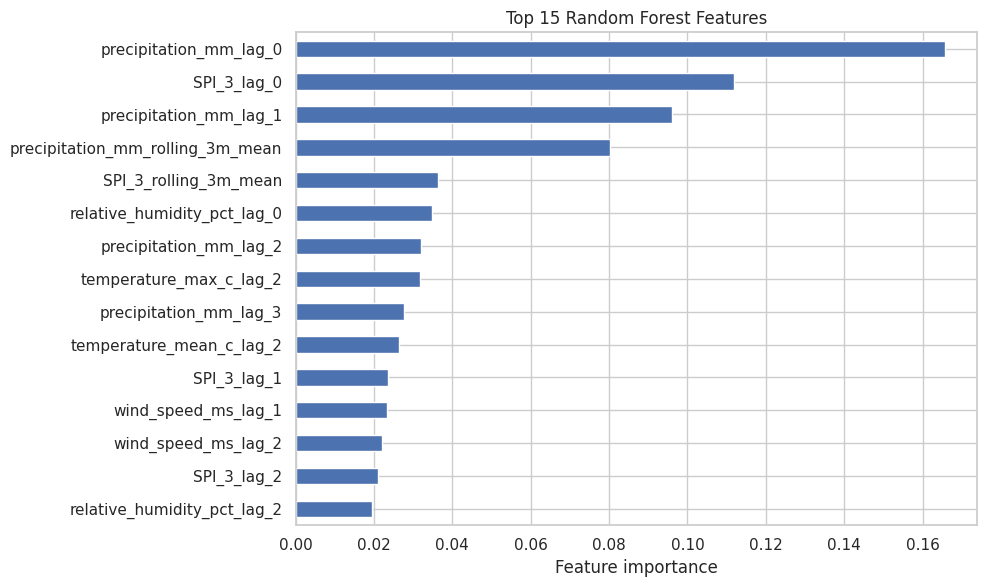

In [40]:
rf_pipeline = trained_models["Random Forest"]
rf_model = rf_pipeline.named_steps["model"]

importance = pd.Series(
    rf_model.feature_importances_,
    index=engineered_features
).sort_values(ascending=False)

display(importance.head(15).to_frame("Random Forest importance"))

plt.figure(figsize=(10, 6))
importance.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Random Forest Features")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

## 6.7 Save the Best Candidate Model

The model with the highest test F1-score is saved as a candidate for further validation. Selecting a model using a single holdout period can be unstable, especially with a limited number of drought events. A future version should add rolling-origin validation and evaluate additional years or locations before operational use.

In [41]:
import joblib
from pathlib import Path

best_model_name = evaluation_results["F1-score"].idxmax()
best_model = trained_models[best_model_name]

Path("models").mkdir(exist_ok=True)
joblib.dump(
    {
        "model": best_model,
        "model_name": best_model_name,
        "features": engineered_features,
        "target": "drought risk in the following month",
        "threshold": "SPI-3 <= -1.0"
    },
    "models/aquasense_drought_risk_model.joblib"
)

evaluation_results.to_csv("reports/model_evaluation.csv")
importance.to_csv("reports/random_forest_feature_importance.csv")

print("Best candidate:", best_model_name)
print("Model saved to models/aquasense_drought_risk_model.joblib")

Best candidate: Logistic Regression
Model saved to models/aquasense_drought_risk_model.joblib


# 7. Interpretation, Limitations and Next Steps

## 7.1 Interpretation

AquaSense currently provides a pilot meteorological drought-monitoring and one-month-ahead drought-risk classification workflow for Kairouan. SPI-3 summarizes precipitation anomalies over a three-month accumulation period. The predictive models use historical climate indicators and calendar information to estimate whether the following month may reach the moderate drought threshold.

## 7.2 Important Limitations

- **Meteorological drought is not crop water stress.** Crop-level assessment requires additional variables such as soil moisture, vegetation indices (for example NDVI), crop type, and irrigation information.
- **Single-location pilot.** Results from Kairouan cannot automatically be generalized to all Tunisian regions.
- **Limited sample size.** Monthly aggregation produces only about 300 observations for 2001–2025. Complex deep-learning models such as LSTM may overfit this dataset.
- **SPI distribution assumptions.** The gamma distribution is a conventional SPI approach, but fit quality and zero-rainfall handling should be checked, especially in arid climates.
- **Historical data are not a forecast feed.** The model predicts from observed historical features; deployment requires reliable and timely input data.
- **Model validation.** A single chronological holdout is an initial experiment, not proof of operational forecasting skill. Rolling-origin validation and comparison against simple persistence/climatology baselines are recommended.

## 7.3 Recommended Future Improvements

1. Add CHIRPS precipitation data and compare it with NASA POWER precipitation.
2. Integrate satellite-derived NDVI and land-surface or soil-moisture indicators.
3. Add additional Tunisian governorates and evaluate spatial generalization.
4. Use rolling-origin time-series validation and probability calibration.
5. Compare predictions with a persistence baseline and a climatological baseline.
6. Build a Streamlit dashboard showing historical indicators, current conditions, and model outputs.
7. Document data provenance, API retrieval dates, model versions, and limitations.

## 7.4 Scientific Scope

Until satellite, soil, and crop observations are incorporated and validated, AquaSense should be described as a **meteorological drought-risk monitoring and prediction prototype**, not as a validated crop water-stress detector or an irrigation recommendation system.

In [42]:
# Final project outputs overview
from pathlib import Path

output_paths = [
    "data/raw/kairouan_weather.csv",
    "data/processed/kairouan_monthly_climate_spi3.csv",
    "data/processed/kairouan_drought_features.csv",
    "models/aquasense_drought_risk_model.joblib",
    "reports/model_evaluation.csv",
    "reports/random_forest_feature_importance.csv"
]

for output_path in output_paths:
    print(f"{'FOUND' if Path(output_path).exists() else 'NOT YET CREATED'}: {output_path}")

FOUND: data/raw/kairouan_weather.csv
FOUND: data/processed/kairouan_monthly_climate_spi3.csv
FOUND: data/processed/kairouan_drought_features.csv
FOUND: models/aquasense_drought_risk_model.joblib
FOUND: reports/model_evaluation.csv
FOUND: reports/random_forest_feature_importance.csv
